In [1]:
import os
import numpy as np
import torch
import util
import matplotlib.pyplot as plt
from data import fr
%matplotlib inline

In [2]:
fr_path = 'pretrained_models/DeepFreq/frequency_representation_module.pth'
fc_path = 'pretrained_models/DeepFreq/frequency_counting_module.pth'
data_dir = 'test_dataset'

### Use GPU or CPU

In [3]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [4]:
#load models
fr_module, _, _, args_fr, _ = util.load(fr_path, 'fr', device)
fc_module, _, _, args_fc, _ = util.load(fc_path, 'fc', device)
fr_module.cpu()
fr_module.eval()
fc_module.cpu()
fc_module.eval()
# Find an FR input length that makes fc_module.mod produce the expected flattened size
def _find_target_fr_size(fc_mod, minL=50, maxL=2000):
    import torch
    for L in range(minL, maxL+1):
        x = torch.zeros(1,1,L)
        for layer in fc_mod.mod:
            x = layer(x)
        if x.view(1,-1).shape[1] == fc_mod.out_layer.in_features:
            return L
    raise RuntimeError('No compatible FR size found for fc_module')
target_fr_size = _find_target_fr_size(fc_module)
print('Using target_fr_size for fc input:', target_fr_size)
xgrid = np.linspace(-0.5, 0.5, fr_module.fr_size, endpoint=False)

Using target_fr_size for fc input: 780


In [5]:
#load data
f = np.load(os.path.join(data_dir, 'f.npy'))
signal_0dB = np.load(os.path.join(data_dir, '0.0dB.npy'))
signal_10dB = np.load(os.path.join(data_dir, '10.0dB.npy'))
signal_50dB = np.load(os.path.join(data_dir, '50.0dB.npy'))
nfreq = nfreq = np.sum(f >= -0.5, axis=1)

### Frequency estimation

In [6]:
idx = 8

In [7]:
with torch.no_grad():
    fr_0dB = fr_module(torch.tensor(signal_0dB[idx][None]))
    fr_10dB = fr_module(torch.tensor(signal_10dB[idx][None]))
    fr_50dB = fr_module(torch.tensor(signal_50dB[idx][None]))
    # Resample frequency representation to match fc_module expected input size if needed
    import torch.nn.functional as F
    try:
        target_size = target_fr_size
    except Exception:
        target_size = fr_0dB.shape[-1]
    def _resample(frvec, target):
        t = frvec.unsqueeze(1)  # shape [bsz, 1, L]
        t = F.interpolate(t, size=target, mode='linear', align_corners=False)
        return t.squeeze(1)
    fr_0dB_rs = _resample(fr_0dB, target_size)
    fr_10dB_rs = _resample(fr_10dB, target_size)
    fr_50dB_rs = _resample(fr_50dB, target_size)
    nestimate_0dB = fc_module(fr_0dB_rs).numpy().round()
    nestimate_10dB = fc_module(fr_10dB_rs).numpy().round()
    nestimate_50dB = fc_module(fr_50dB_rs).numpy().round()
fr_0dB = fr_0dB.numpy()    
fr_10dB = fr_10dB.numpy()    
fr_50dB = fr_50dB.numpy()

Number of frequencies:

In [8]:
nfreq[idx]

np.int64(9)

Estimated number of frequencies 0dB/10dB/50dB:

In [9]:
nestimate_0dB[0, 0], nestimate_10dB[0, 0], nestimate_50dB[0, 0]

(np.float32(7.0), np.float32(6.0), np.float32(7.0))

Compute frequency estimates:

In [10]:
# Ensure nestimate arrays are 1-D integer arrays
import numpy as _np
nestimate_0dB = _np.asarray(nestimate_0dB).round().astype(int).reshape(-1)
nestimate_10dB = _np.asarray(nestimate_10dB).round().astype(int).reshape(-1)
nestimate_50dB = _np.asarray(nestimate_50dB).round().astype(int).reshape(-1)
f_estimate_0dB = fr.find_freq(fr_0dB, nestimate_0dB, xgrid)
f_estimate_10dB = fr.find_freq(fr_10dB, nestimate_10dB, xgrid)
f_estimate_50dB = fr.find_freq(fr_50dB, nestimate_50dB, xgrid)

### 50dB

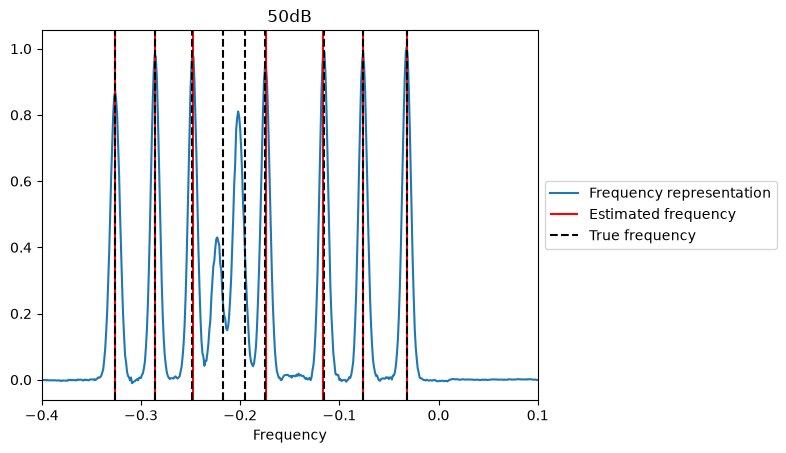

In [11]:
fig, ax = plt.subplots()
ax.plot(xgrid, fr_50dB[0], label='Frequency representation')
ylim = ax.get_ylim()
ff = f[idx][f[idx] > -1]
f_model = f_estimate_50dB[f_estimate_50dB > -1]
ax.vlines(f_model, ymin=ylim[0], ymax=ylim[1], color='r', label='Estimated frequency')
ax.vlines(ff, linestyle='--', ymin=ylim[0], ymax=ylim[1], color='k', label='True frequency')
ax.set_ylim(ylim)
ax.set_xlim(-0.4, 0.1)
ax.set_xlabel('Frequency')
ax.set_title('50dB')
ax.legend( loc='center left', bbox_to_anchor=(1, 0.5))

### 10dB

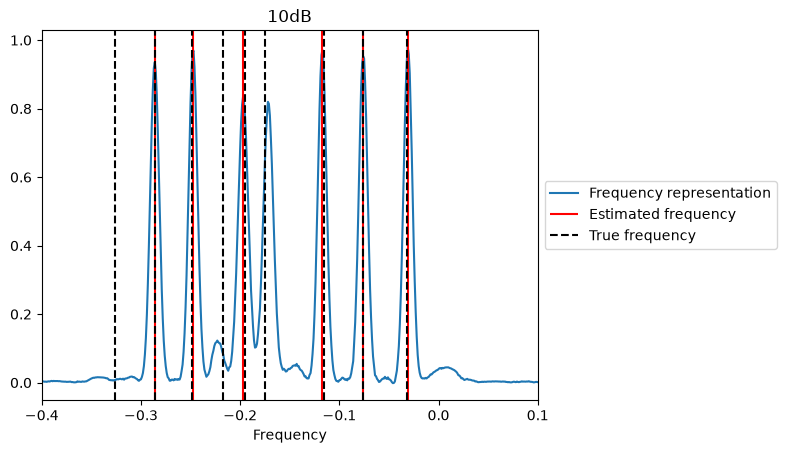

In [12]:
fig, ax = plt.subplots()
ax.plot(xgrid, fr_10dB[0], label='Frequency representation')
ylim = ax.get_ylim()
ff = f[idx][f[idx] > -1]
f_model = f_estimate_10dB[f_estimate_10dB > -1]
ax.vlines(f_model, ymin=ylim[0], ymax=ylim[1], color='r', label='Estimated frequency')
ax.vlines(ff, linestyle='--', ymin=ylim[0], ymax=ylim[1], color='k', label='True frequency')
ax.set_ylim(ylim)
ax.set_xlim(-0.4, 0.1)
ax.set_xlabel('Frequency')
ax.set_title('10dB')
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))

### 0dB

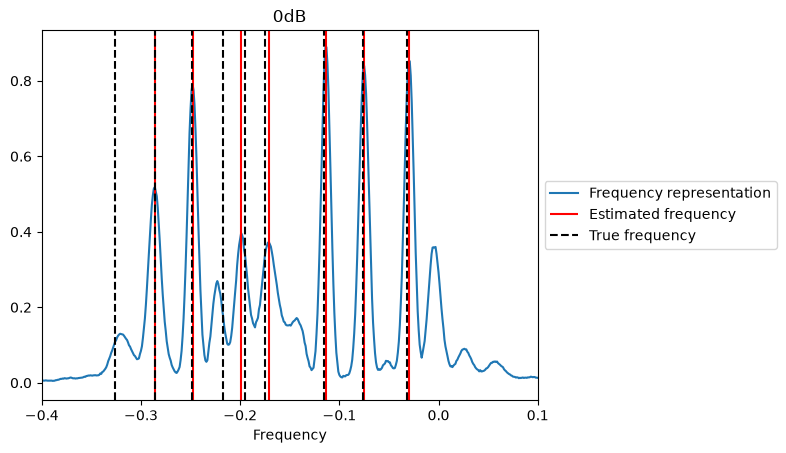

In [13]:
fig, ax = plt.subplots()
ax.plot(xgrid, fr_0dB[0], label='Frequency representation')
ylim = ax.get_ylim()
ff = f[idx][f[idx] > -1]
f_model = f_estimate_0dB[f_estimate_0dB > -1]
ax.vlines(f_model, ymin=ylim[0], ymax=ylim[1], color='r', label='Estimated frequency')
ax.vlines(ff, linestyle='--', ymin=ylim[0], ymax=ylim[1], color='k', label='True frequency')
ax.set_ylim(ylim)
ax.set_xlim(-0.4, 0.1)
ax.set_xlabel('Frequency')
ax.set_title('0dB')
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))

### Impact of the noise

In [14]:
idx = 13
with torch.no_grad():
    fr_0dB = fr_module(torch.tensor(signal_0dB[idx][None])).numpy()[0]
    fr_10dB = fr_module(torch.tensor(signal_10dB[idx][None])).numpy()[0]
    fr_50dB = fr_module(torch.tensor(signal_50dB[idx][None])).numpy()[0]

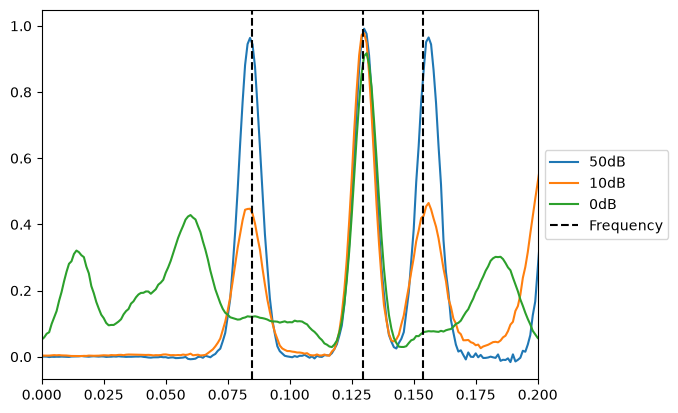

In [15]:
fig, ax = plt.subplots()
ax.plot(xgrid, fr_50dB, label='50dB')
ax.plot(xgrid, fr_10dB, label='10dB')
ax.plot(xgrid, fr_0dB, label='0dB')
ylim = ax.get_ylim()
ff = f[idx][f[idx] > -1]
ax.vlines(ff, ymin=ylim[0], ymax=ylim[1], linestyle='--', color='k', label='Frequency')
ax.set_ylim(ylim)
ax.set_xlim(0., 0.2)
ax.legend(loc='center left', bbox_to_anchor=(1, 0.5))

### Comparison with other methods

In [16]:
idx = 13

In [17]:
signal_50dB_c = signal_50dB[:, 0]+ 1j * signal_50dB[:, 1]
signal_10dB_c = signal_10dB[:, 0]+ 1j * signal_10dB[:, 1]

In [18]:
with torch.no_grad():
    fr_10dB = fr_module(torch.tensor(signal_10dB[idx][None]))[0]
    fr_50dB = fr_module(torch.tensor(signal_50dB[idx][None]))[0]
music_fr_10dB = fr.music(signal_10dB_c[idx][None], xgrid, nfreq[idx][None])[0]
periodogram_10dB = fr.periodogram(signal_10dB_c[idx][None], xgrid)[0]
music_fr_50dB = fr.music(signal_50dB_c[idx][None], xgrid, nfreq[idx][None])[0]
periodogram_50dB = fr.periodogram(signal_50dB_c[idx][None], xgrid)[0]

fr_10dB = fr_10dB.cpu().data.numpy()
fr_50dB = fr_50dB.cpu().data.numpy()

#### Note:
The following code requires `matlab.engine` to work. Please refer https://www.mathworks.com/help/matlab/matlab_external/install-the-matlab-engine-for-python.html for detailed installation instructions. Run

In [19]:
# Disable CBLasso MATLAB dependency when matlab.engine is not available
cbl = False
if cbl:
    import sys
    # sys.path.append('/usr/local/lib/python3.5/dist-packages/')
    import matlab.engine
    eng = matlab.engine.start_matlab()
    eng.cd(r'cblasso')

In [20]:
if cbl:
    res_10dB = eng.polynomial(matlab.double(list(signal_10dB_c[idx]), is_complex=True))
    res_10dB = np.asarray(res_10dB)
    cbl_10dB = np.roll(res_10dB[:, 0], fr_module.fr_size//2)
    res_50dB = eng.polynomial(matlab.double(list(signal_50dB_c[idx]), is_complex=True))
    res_50dB = np.asarray(res_50dB)
    cbl_50dB = np.roll(res_50dB[:, 0], fr_module.fr_size//2)
    grid = np.roll(res_50dB[:, 1], fr_module.fr_size//2)
    grid[grid >= 0.5] -= 1

# 50dB

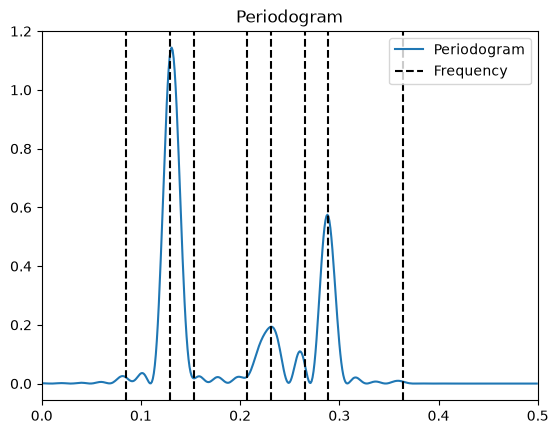

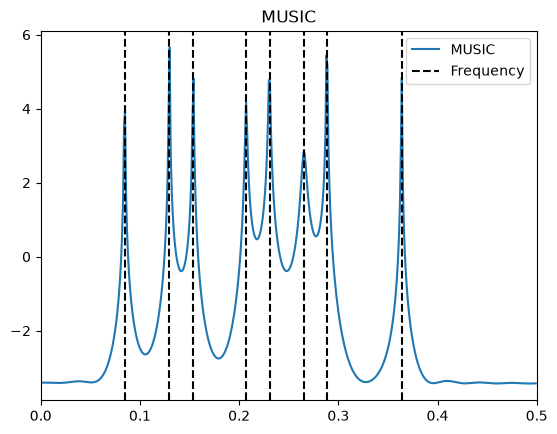

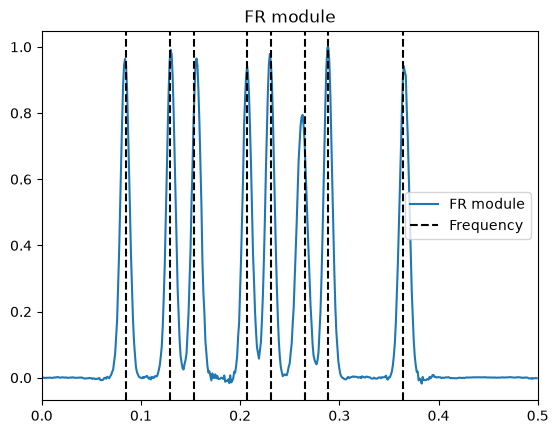

In [21]:
fig, ax = plt.subplots()
ax.plot(xgrid, periodogram_50dB, label='Periodogram')
ylim = ax.get_ylim()
ff = f[idx][f[idx] > -1]
ax.vlines(ff, ymin=ylim[0], ymax=ylim[1], linestyle='--', color='k', label='Frequency')
ax.set_ylim(ylim)
ax.set_xlim(0, 0.5)
ax.set_title('Periodogram')
ax.legend()
plt.show()

fig, ax = plt.subplots()
ax.plot(xgrid, music_fr_50dB, label='MUSIC')
ylim = ax.get_ylim()
ff = f[idx][f[idx] > -1]
ax.vlines(ff, ymin=ylim[0], ymax=ylim[1], linestyle='--', color='k', label='Frequency')
ax.set_ylim(ylim)
ax.set_xlim(0, 0.5)
ax.set_title('MUSIC')
ax.legend()
plt.show()

if cbl:
    fig, ax = plt.subplots()
    ax.plot(grid, np.abs(cbl_50dB), label='CBLasso')
    ylim = ax.get_ylim()
    ff = f[idx][f[idx] > -1]
    ax.vlines(ff, ymin=ylim[0], ymax=ylim[1], linestyle='--', color='k', label='Frequency')
    ax.set_ylim(ylim)
    ax.set_xlim(0, 0.5)
    ax.set_title('CBLasso')
    ax.legend()
    plt.show()

fig, ax = plt.subplots()
ax.plot(xgrid, fr_50dB, label='FR module')
ylim = ax.get_ylim()
ff = f[idx][f[idx] > -1]
ax.vlines(ff, ymin=ylim[0], ymax=ylim[1], linestyle='--', color='k', label='Frequency')
ax.set_ylim(ylim)
ax.set_xlim(0, 0.5)
ax.set_title('FR module')
ax.legend()
plt.show()

# 10dB

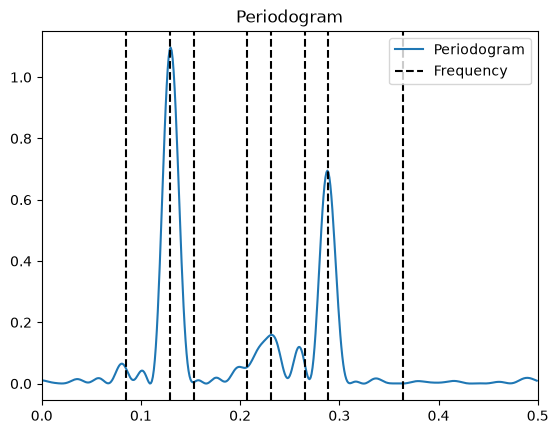

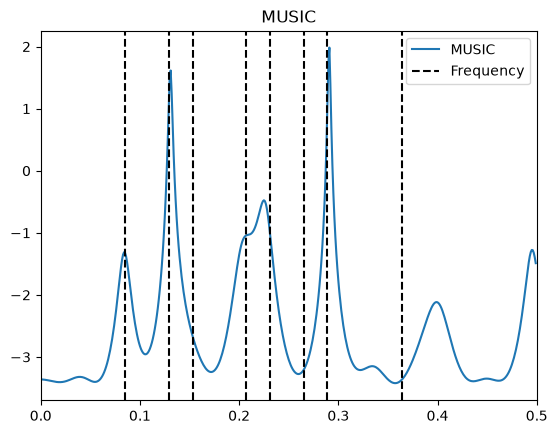

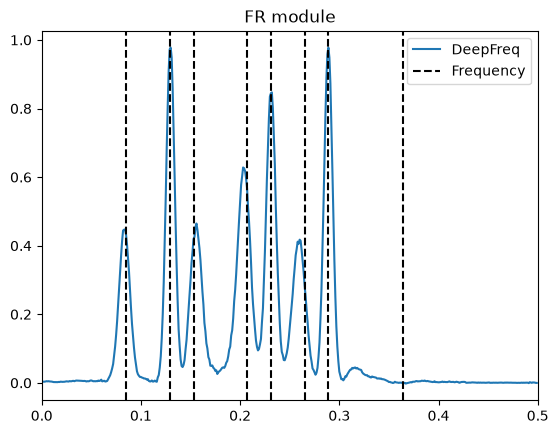

In [22]:
fig, ax = plt.subplots()
ax.plot(xgrid, periodogram_10dB, label='Periodogram')
ylim = ax.get_ylim()
ff = f[idx][f[idx] > -1]
ax.vlines(ff, ymin=ylim[0], ymax=ylim[1], linestyle='--', color='k', label='Frequency')
ax.set_ylim(ylim)
ax.set_xlim(0, 0.5)
ax.set_title('Periodogram')
ax.legend()
plt.show()

fig, ax = plt.subplots()
ax.plot(xgrid, music_fr_10dB, label='MUSIC')
ylim = ax.get_ylim()
ff = f[idx][f[idx] > -1]
ax.vlines(ff, ymin=ylim[0], ymax=ylim[1], linestyle='--', color='k', label='Frequency')
ax.set_ylim(ylim)
ax.set_xlim(0, 0.5)
ax.set_title('MUSIC')
ax.legend()
plt.show()

if cbl:
    fig, ax = plt.subplots()
    ax.plot(grid, np.abs(cbl_10dB), label='CBLasso')
    ylim = ax.get_ylim()
    ff = f[idx][f[idx] > -1]
    ax.vlines(ff, ymin=ylim[0], ymax=ylim[1], linestyle='--', color='k', label='Frequency')
    ax.set_ylim(ylim)
    ax.set_xlim(0, 0.5)
    ax.set_title('CBLasso')
    ax.legend()
    plt.show()

fig, ax = plt.subplots()
ax.plot(xgrid, fr_10dB, label='DeepFreq')
ylim = ax.get_ylim()
ff = f[idx][f[idx] > -1]
ax.vlines(ff, ymin=ylim[0], ymax=ylim[1], linestyle='--', color='k', label='Frequency')
ax.set_ylim(ylim)
ax.set_xlim(0, 0.5)
ax.set_title('FR module')
ax.legend()
plt.show()